# **EXPLORATORY DATA ANALYSIS**

In [1]:
pip install pydicom nibabel simpleitk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip install pyvista

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## **DISTRIBUTION OF VOXEL SPACING $dx$, $dy$, $dz$**

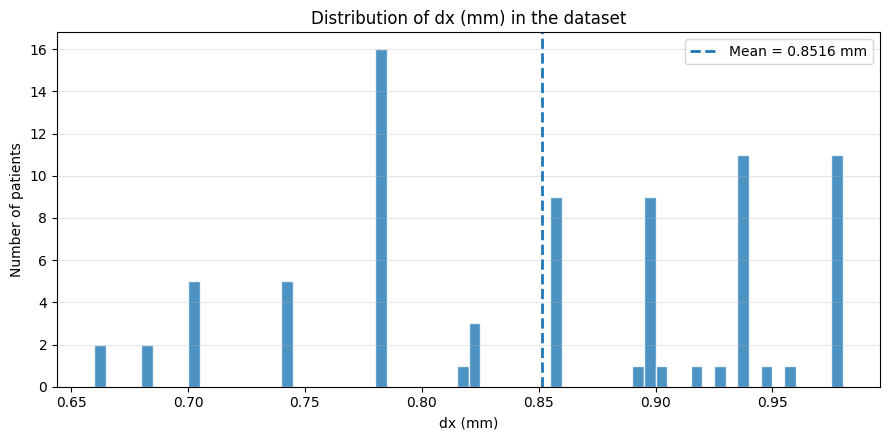

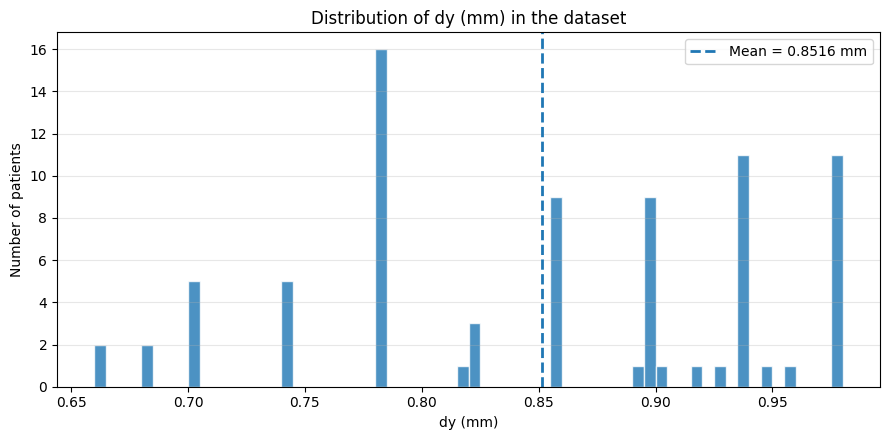

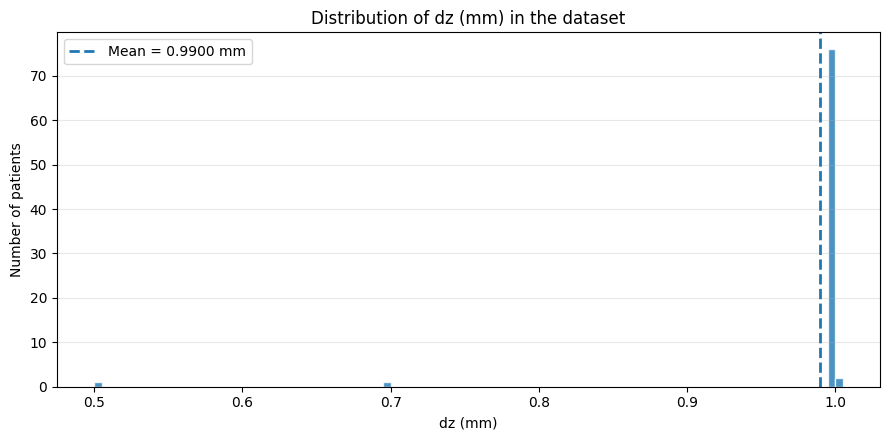

In [35]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

labels_folder = 'TCIA_pancreas_labels-02-05-2017'

dxs, dys, dzs = [], [], []

for file_name in sorted(os.listdir(labels_folder)):
    if file_name.endswith('.nii.gz'):
        file_path = os.path.join(labels_folder, file_name)
        nii = nib.load(file_path)
        dx, dy, dz = nii.header.get_zooms()[:3]
        dxs.append(float(dx))
        dys.append(float(dy))
        dzs.append(float(dz))

dxs = np.array(dxs)
dys = np.array(dys)
dzs = np.array(dzs)

BIN_WIDTH = 0.005

def plot_hist(values, title, xlabel):
    vmin, vmax = float(values.min()), float(values.max())
    bins = np.arange(np.floor(vmin / BIN_WIDTH) * BIN_WIDTH,
                     np.ceil(vmax / BIN_WIDTH) * BIN_WIDTH + BIN_WIDTH,
                     BIN_WIDTH)
    mean_v = float(values.mean())

    plt.figure(figsize=(9, 4.5))
    plt.hist(values, bins=bins, edgecolor='white', alpha=0.8)
    plt.axvline(mean_v, linestyle='--', linewidth=2, label=f"Mean = {mean_v:.4f} mm")
    plt.xlabel(xlabel)
    plt.ylabel("Number of patients")
    plt.title(title)
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_hist(dxs, "Distribution of dx (mm) in the dataset", "dx (mm)")
plot_hist(dys, "Distribution of dy (mm) in the dataset", "dy (mm)")
plot_hist(dzs, "Distribution of dz (mm) in the dataset", "dz (mm)")

In [5]:
import os
import nibabel as nib
from collections import Counter
import numpy as np

labels_folder = 'C:\\Users\\pietr\\Desktop\\Progetto ai\\vecchie da cancellare\\TCIA_pancreas_labels-02-05-2017'

dz_values = []

for file_name in sorted(os.listdir(labels_folder)):
    if file_name.endswith('.nii.gz'):
        file_path = os.path.join(labels_folder, file_name)
        nii = nib.load(file_path)
        dz = float(nii.header.get_zooms()[2])  # convertiamo a float normale
        dz_values.append(round(dz, 3))  # arrotondiamo per evitare 1.0000001

counter = Counter(dz_values)

print("Conteggio dz per paziente:")
for dz, count in sorted(counter.items()):
    print(f"dz = {dz} mm  →  {count} pazienti")

Conteggio dz per paziente:
dz = 0.5 mm  →  1 pazienti
dz = 0.7 mm  →  1 pazienti
dz = 1.0 mm  →  78 pazienti


In [7]:
# I want to know which are the patients with dz = 0.5 mm and dz = 0.7 mm
patients_dz_05 = []
patients_dz_07 = []
for file_name in sorted(os.listdir(labels_folder)):
    if file_name.endswith('.nii.gz'):
        file_path = os.path.join(labels_folder, file_name)
        nii = nib.load(file_path)
        dz = float(nii.header.get_zooms()[2])
        dz_rounded = round(dz, 3)
        if dz_rounded == 0.5:
            patients_dz_05.append(file_name)
        elif dz_rounded == 0.7:
            patients_dz_07.append(file_name)
print("\nPazienti con dz = 0.5 mm:")
for patient in patients_dz_05:
    print(patient)
print("\nPazienti con dz = 0.7 mm:")
for patient in patients_dz_07:
    print(patient)


Pazienti con dz = 0.5 mm:
label0044.nii.gz

Pazienti con dz = 0.7 mm:
label0058.nii.gz


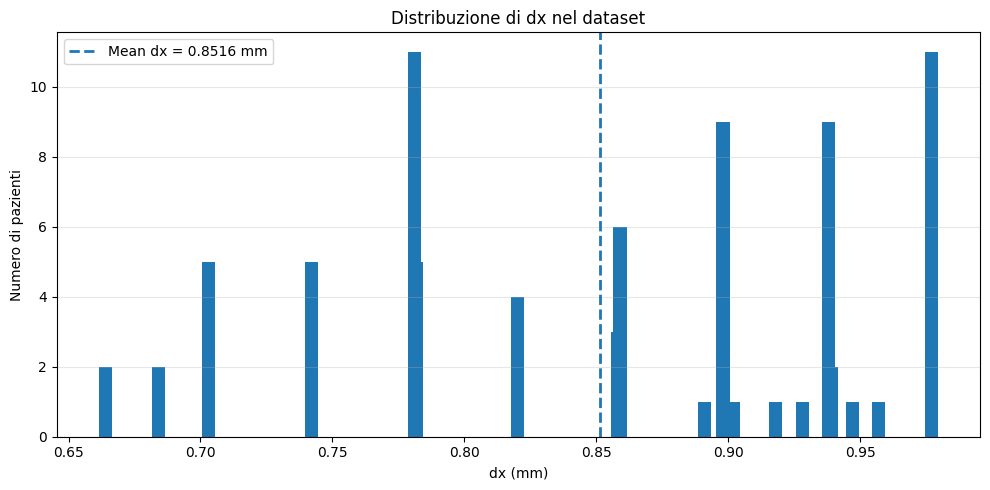

In [33]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from collections import Counter

labels_folder = 'TCIA_pancreas_labels-02-05-2017'

# 1) Leggi dx per ogni paziente
dx_values = []
for file_name in sorted(os.listdir(labels_folder)):
    if file_name.endswith('.nii.gz'):
        file_path = os.path.join(labels_folder, file_name)
        nii = nib.load(file_path)
        dx = float(nii.header.get_zooms()[0])
        dx_values.append(dx)

dx_values = np.array(dx_values, dtype=float)

# 2) Raggruppa per valori "uguali" (round per evitare floating noise)
dx_rounded = np.round(dx_values, 3)
counter = Counter(dx_rounded)

# 3) Prepara dati per il plot
xs = np.array(sorted(counter.keys()), dtype=float)
ys = np.array([counter[x] for x in xs], dtype=int)

mean_dx = float(np.mean(dx_values))

# 4) Plot
plt.figure(figsize=(10, 5))
plt.bar(xs, ys, width=0.005)  # width puoi aumentarlo se vuoi barre più larghe
plt.axvline(mean_dx, linestyle='--', linewidth=2,
            label=f"Mean dx = {mean_dx:.4f} mm")

plt.xlabel("dx (mm)")
plt.ylabel("Numero di pazienti")
plt.title("Distribuzione di dx nel dataset")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
import os
import nibabel as nib
from collections import defaultdict

labels_folder = 'TCIA_pancreas_labels-02-05-2017'

dz_dict = defaultdict(list)

for file_name in sorted(os.listdir(labels_folder)):
    if file_name.endswith('.nii.gz'):
        file_path = os.path.join(labels_folder, file_name)
        nii = nib.load(file_path)
        
        dz = float(nii.header.get_zooms()[2])
        dz = round(dz, 3)  # evita problemi 1.0000001
        
        dz_dict[dz].append(file_name)

print("Distribuzione dz nel dataset:\n")

for dz in sorted(dz_dict.keys()):
    print(f"dz = {dz} mm  →  {len(dz_dict[dz])} pazienti")
    print("   Pazienti:", dz_dict[dz])
    print()

Distribuzione dz nel dataset:

dz = 0.5 mm  →  1 pazienti
   Pazienti: ['label0044.nii.gz']

dz = 0.7 mm  →  1 pazienti
   Pazienti: ['label0058.nii.gz']

dz = 1.0 mm  →  78 pazienti
   Pazienti: ['label0001.nii.gz', 'label0002.nii.gz', 'label0003.nii.gz', 'label0004.nii.gz', 'label0005.nii.gz', 'label0006.nii.gz', 'label0007.nii.gz', 'label0008.nii.gz', 'label0009.nii.gz', 'label0010.nii.gz', 'label0011.nii.gz', 'label0012.nii.gz', 'label0013.nii.gz', 'label0014.nii.gz', 'label0015.nii.gz', 'label0016.nii.gz', 'label0017.nii.gz', 'label0018.nii.gz', 'label0019.nii.gz', 'label0020.nii.gz', 'label0021.nii.gz', 'label0022.nii.gz', 'label0023.nii.gz', 'label0024.nii.gz', 'label0026.nii.gz', 'label0027.nii.gz', 'label0028.nii.gz', 'label0029.nii.gz', 'label0030.nii.gz', 'label0031.nii.gz', 'label0032.nii.gz', 'label0033.nii.gz', 'label0034.nii.gz', 'label0035.nii.gz', 'label0036.nii.gz', 'label0037.nii.gz', 'label0038.nii.gz', 'label0039.nii.gz', 'label0040.nii.gz', 'label0041.nii.gz', 'la

## **3D VISUALIZATION**

Volume Shape: (512, 512, 218)
Mesh generated: 42370 vertices and 84796 faces.


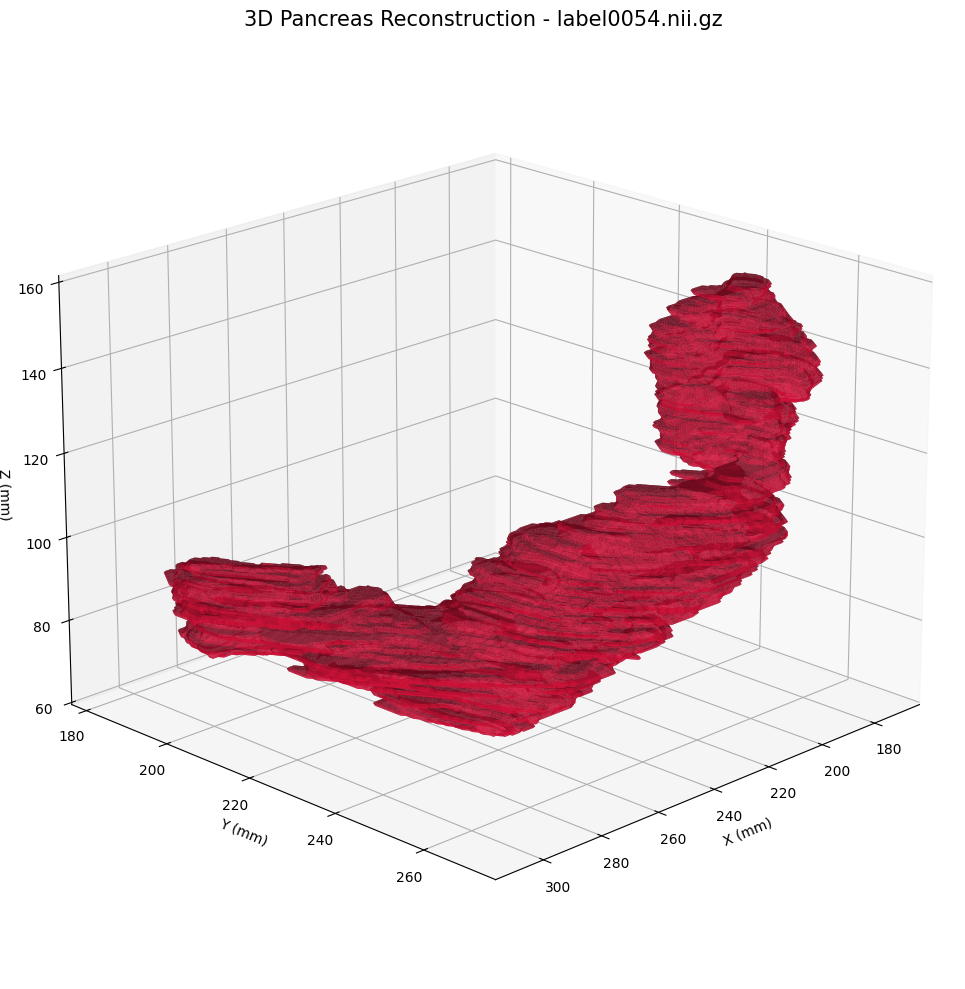

In [3]:
import os
import numpy as np
import nibabel as nib
from skimage import measure
import matplotlib.pyplot as plt

# ====== CONFIGURATION ======
file_path = r"C:\Users\pietr\Desktop\Progetto ai\first steps\TCIA_pancreas_labels-02-05-2017\label0054.nii.gz"
file_name = os.path.basename(file_path)

# ====== DATA LOADING ======
if not os.path.exists(file_path):
    print(f"ERROR: File not found at {file_path}")
else:
    nii = nib.load(file_path)
    mask_data = nii.get_fdata()
    
    # Dimensioni voxel per mantenere le proporzioni anatomiche correte
    dx, dy, dz = nii.header.get_zooms()[:3]
    
    print(f"Volume Shape: {mask_data.shape}")

    # ====== MARCHING CUBES (3D Reconstruction) ======
    # Generazione mesh con livello 0.5 (standard per maschere binarie)
    verts, faces, normals, values = measure.marching_cubes(mask_data, level=0.5)
    
    # Scaliamo i vertici in coordinate reali (mm)
    verts[:, 0] *= dx
    verts[:, 1] *= dy
    verts[:, 2] *= dz

    print(f"Mesh generated: {verts.shape[0]} vertices and {faces.shape[0]} faces.")

    # ====== VISUALIZATION (Stile plot_trisurf) ======
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, projection="3d")

    # Utilizzo di plot_trisurf come richiesto
    # Nota: passiamo X, Y, le facce (triangles) e Z
    ax.plot_trisurf(
        verts[:, 0], 
        verts[:, 1], 
        faces, 
        verts[:, 2], 
        color='crimson',  # Colore uniforme
        lw=0.1,           # Spessore linee dei triangoli (molto sottile)
        alpha=0.8,        # Trasparenza
        antialiased=True
    )

    # Titoli e Label
    ax.set_title(f"3D Pancreas Reconstruction - {file_name}", fontsize=15)
    ax.set_xlabel("X (mm)")
    ax.set_ylabel("Y (mm)")
    ax.set_zlabel("Z (mm)")

    # Ottimizzazione della visualizzazione
    ax.view_init(elev=20, azim=45)

    plt.tight_layout()
    plt.show()

## **PANCREAS SPATIAL DISTRIBUTION ACROSS CT SLIDES**

Mean and variability of pancreas pixel distribution along the axial (z-axis) dimension across 80 contrast-enhanced CT volumes, highlighting the typical anatomical location and inter-patient variability.

In [11]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import os

# --- CONFIGURATION ---
labels_folder = r'C:\Users\pietr\Desktop\Progetto ai\vecchie da cancellare\TCIA_pancreas_labels-02-05-2017'
all_label_files = sorted([f for f in os.listdir(labels_folder) if f.endswith('.nii.gz')])

# We will process all available files (should be 82)
target_files = all_label_files 
num_patients = len(target_files)

print(f"Starting analysis for {num_patients} patients...")

Starting analysis for 80 patients...


In [12]:
all_distributions = []
max_slices = 0

for i, file_name in enumerate(target_files):
    file_path = os.path.join(labels_folder, file_name)
    
    # Load and process
    mask_data = nib.load(file_path).get_fdata()
    dist = np.sum(mask_data, axis=(0, 1))
    
    all_distributions.append(dist)
    
    # Update max length for later alignment
    if len(dist) > max_slices:
        max_slices = len(dist)
        
    # Progress update every 10 patients
    if (i + 1) % 10 == 0 or (i + 1) == num_patients:
        print(f"Processed {i + 1}/{num_patients} patients...")

print("All patients processed successfully.")

Processed 10/80 patients...
Processed 20/80 patients...
Processed 30/80 patients...
Processed 40/80 patients...
Processed 50/80 patients...
Processed 60/80 patients...
Processed 70/80 patients...
Processed 80/80 patients...
All patients processed successfully.


In [13]:
# Pad arrays to the same length (max_slices)
padded_matrix = np.zeros((num_patients, max_slices))

for i, dist in enumerate(all_distributions):
    padded_matrix[i, :len(dist)] = dist

# Compute Statistics
mean_dist = np.mean(padded_matrix, axis=0)
std_dist = np.std(padded_matrix, axis=0)
# Calculate a 95% Confidence Interval (approx. 1.96 * SEM or just use 1 STD for visualization)
upper_bound = mean_dist + std_dist
lower_bound = np.maximum(0, mean_dist - std_dist) # Ensure we don't go below 0 pixels

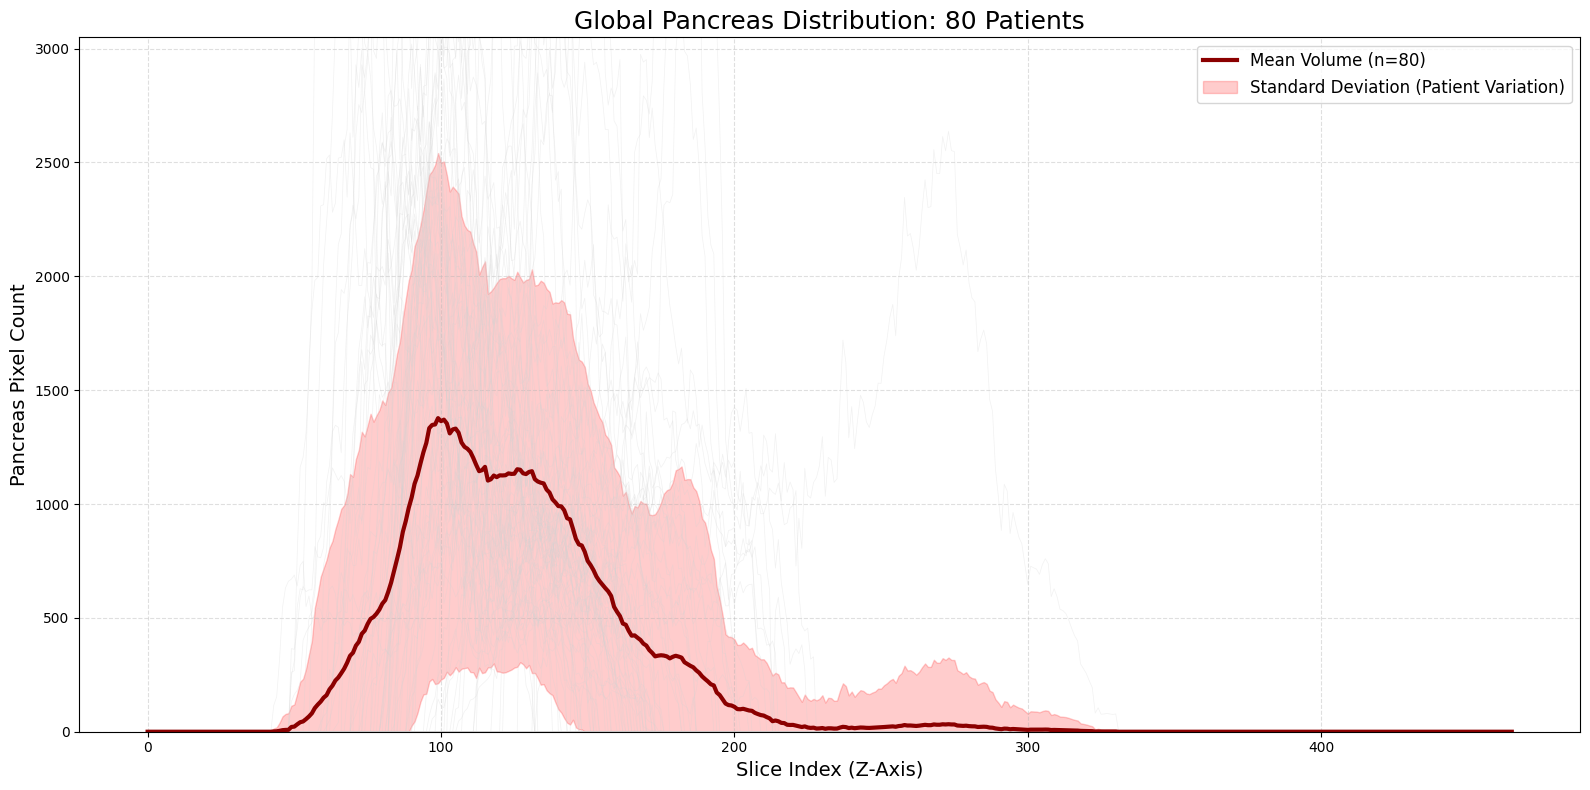

In [14]:
plt.figure(figsize=(16, 8))

# 1. Plot the "Cloud" of individual patient data (very light grey)
plt.plot(padded_matrix.T, color='lightgray', alpha=0.3, linewidth=0.5)

# 2. Plot the Mean (Bold Line)
plt.plot(mean_dist, color='darkred', linewidth=3, label=f'Mean Volume (n={num_patients})')

# 3. Plot the Standard Deviation Shading
plt.fill_between(range(max_slices), lower_bound, upper_bound, 
                 color='red', alpha=0.2, label='Standard Deviation (Patient Variation)')

# 4. Final Formatting
plt.title(f"Global Pancreas Distribution: {num_patients} Patients", fontsize=18)
plt.xlabel("Slice Index (Z-Axis)", fontsize=14)
plt.ylabel("Pancreas Pixel Count", fontsize=14)
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.legend(loc='upper right', fontsize=12)

# Set Y-axis to focus on the data
plt.ylim(0, np.max(upper_bound) * 1.2)

plt.tight_layout()
plt.show()

In [ ]:
start_range = 100
end_range = 130
threshold_percentage = 0.2 

# 1. Calculate the sum of pixels in the range for each patient
core_volumes = np.sum(padded_matrix[:, start_range:end_range], axis=1)

# 2. Calculate the average of the group in that range
group_average_core = np.mean(core_volumes)
threshold_value = group_average_core * threshold_percentage

# 3. Identify patients below the threshold
low_pixel_patients = np.where(core_volumes < threshold_value)[0]

print(f"Media pixel nel range {start_range}-{end_range}: {int(group_average_core)}")
print(f"Soglia impostata (20% della media): {int(threshold_value)}")
print("-" * 30)

if len(low_pixel_patients) > 0:
    print(f"Trovati {len(low_pixel_patients)} pazienti con pochi pixel:")
    for idx in low_pixel_patients:
        patient_file = target_files[idx]
        actual_volume = int(core_volumes[idx])
        print(f"- Indice: {idx} | File: {patient_file} | Pixel nel range: {actual_volume}")
else:
    print("Nessun paziente sotto soglia trovato con i parametri attuali.")

Media pixel nel range 100-130: 35997
Soglia impostata (20% della media): 7199
------------------------------
Trovati 7 pazienti con pochi pixel:
- Indice: 15 | File: label0016.nii.gz | Pixel nel range: 0
- Indice: 21 | File: label0022.nii.gz | Pixel nel range: 0
- Indice: 23 | File: label0024.nii.gz | Pixel nel range: 0
- Indice: 28 | File: label0030.nii.gz | Pixel nel range: 0
- Indice: 42 | File: label0044.nii.gz | Pixel nel range: 0
- Indice: 48 | File: label0050.nii.gz | Pixel nel range: 3706
- Indice: 51 | File: label0053.nii.gz | Pixel nel range: 0


The reason why patients 15, 21, 23, etc., show 0 pixels in the 100-130 range isn't because they lack a pancreas, but because the scans are not aligned in the same way for everyone.

Patient 1: The technician started the CT scan "higher up," so the pancreas falls at slice 126.

Patient 15: Perhaps the CT scan started lower down, or the volume has fewer total slices, and their pancreas is located at slice 30 or slice 210.

In your global plot, you can see how wide the gray "cloud" is. That confirms that each patient has the organ at a different "Z" position.

## **INITIAL VISUALISATION**

Pancreas found between slice 186 and 330


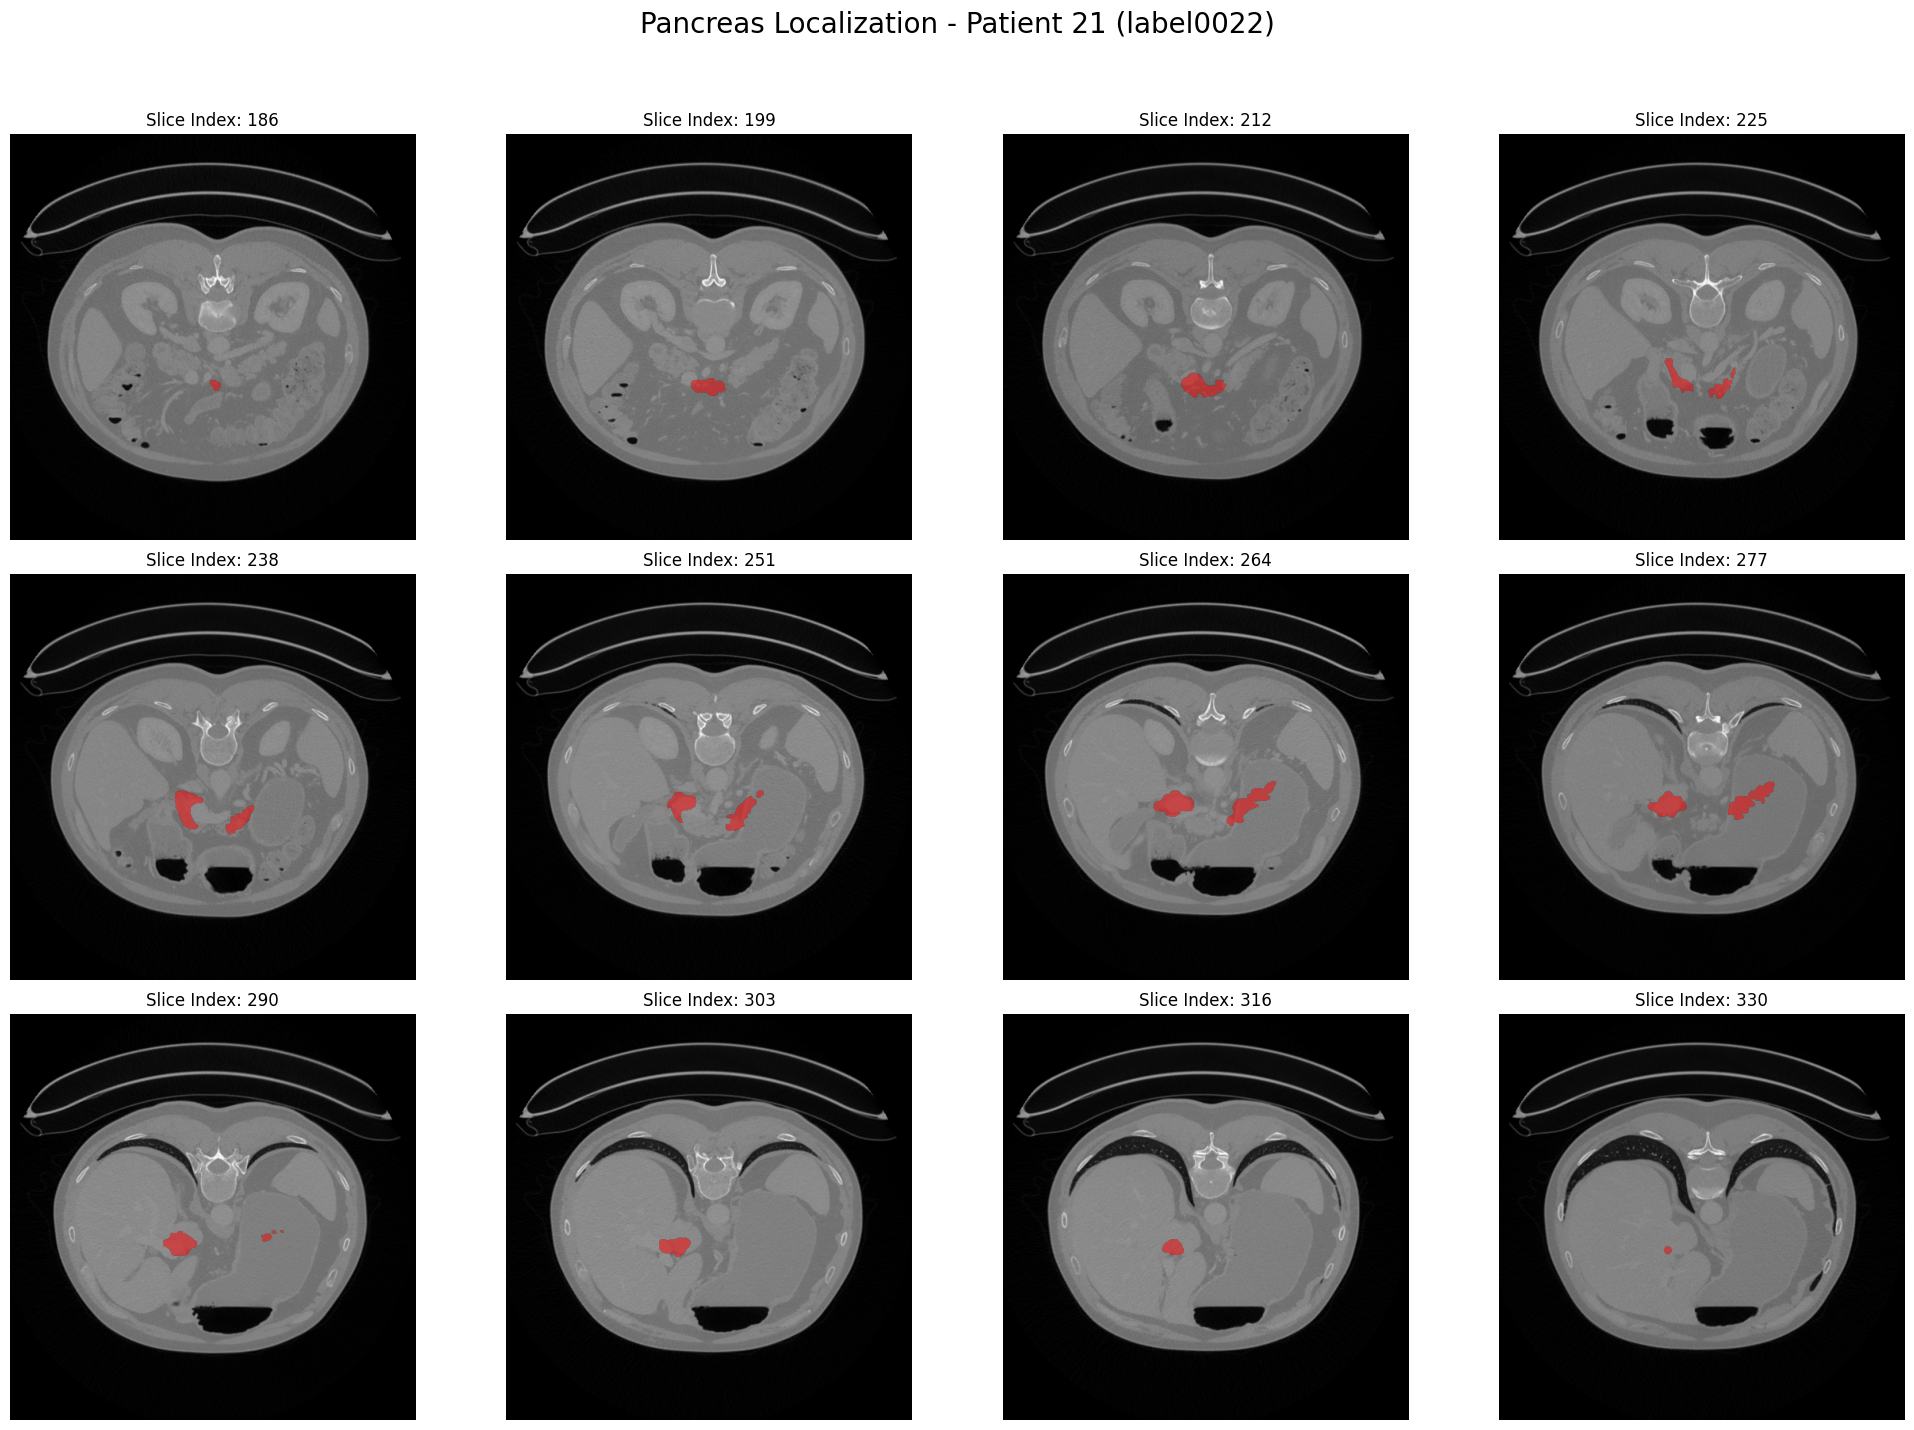

In [10]:
import os
import pydicom
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

# --- CONFIGURATION ---
# Patient 15 corresponds to label0016 based on your previous output
mask_path = r'C:\Users\pietr\Desktop\Progetto ai\vecchie da cancellare\TCIA_pancreas_labels-02-05-2017\label0044.nii.gz'
base_dicom_dir = r'C:\Users\pietr\Desktop\Progetto ai\vecchie da cancellare\PANCREAS-CT'

# 1. Find the correct DICOM subfolder for this patient
# Note: In TCIA, Patient 15's images are in a specific subfolder. 
# This logic searches for the folder containing the actual .dcm files.
dicom_folder = ""
for root, dirs, files in os.walk(base_dicom_dir):
    # Adjust 'Pancreas-CT-0016' or similar if your folder structure uses patient IDs
    if "Pancreas-CT-0044" in root or "PANCREAS_0044" in root: 
        dcm_files = [f for f in files if f.endswith('.dcm')]
        if len(dcm_files) > 100:
            dicom_folder = root
            break

# 2. Load the Mask and find "Active" slices
mask_obj = nib.load(mask_path)
mask_data = mask_obj.get_fdata()

# Find indices where the pancreas (pixel value > 0) exists
pancreas_indices = np.where(np.sum(mask_data, axis=(0, 1)) > 0)[0]

if len(pancreas_indices) == 0:
    print("Error: No pancreas found in this label file!")
else:
    print(f"Pancreas found between slice {pancreas_indices[0]} and {pancreas_indices[-1]}")

    # 3. Load and Sort DICOM Slices
    files = sorted([f for f in os.listdir(dicom_folder) if f.endswith('.dcm')])
    slices = [pydicom.dcmread(os.path.join(dicom_folder, f)) for f in files]
    slices.sort(key=lambda x: float(x.ImagePositionPatient[2]))
    image_volume = np.stack([s.pixel_array for s in slices])

    # 4. Select a subset of slices to display (e.g., 12 slices)
    # We pick 12 evenly spaced slices from the range where the pancreas exists
    display_indices = np.linspace(pancreas_indices[0], pancreas_indices[-1], 12, dtype=int)

    # 5. Plotting the Grid
    fig, axes = plt.subplots(3, 4, figsize=(20, 15))
    axes = axes.flatten()

    for i, idx in enumerate(display_indices):
        ax = axes[i]
        
        # Display CT Image
        ax.imshow(image_volume[idx], cmap='gray')
        
        # Overlay Mask (Transpose might be needed for alignment as seen before)
        mask_slice = mask_data[:, :, idx].T
        masked = np.ma.masked_where(mask_slice == 0, mask_slice)
        ax.imshow(masked, cmap='autumn', alpha=0.5)
        
        ax.set_title(f"Slice Index: {idx}")
        ax.axis('off')

    plt.suptitle(f"Pancreas Localization - Patient 21 (label0022)", fontsize=20)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

## **DISTRIBUTION OF PANCREAS VOLUME**

### Histogram and Boxplot of Pancreas Volumes

Histogram and boxplot of pancreas volumes (cm³) computed using voxel dimensions according to:

$$
V = \sum_i dx \cdot dy \cdot dz
$$

**where:**
- \( dx \) corresponds to `PixelSpacing_x`
- \( dy \) corresponds to `PixelSpacing_y`
- \( dz \) corresponds to `SliceThickness`

The plot highlights the overall distribution and inter-patient variability across 30 CT scans.

In [16]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import os

# --- CONFIGURATION ---
labels_folder = r'C:\Users\pietr\Desktop\Progetto ai\vecchie da cancellare\TCIA_pancreas_labels-02-05-2017'
all_label_files = sorted([f for f in os.listdir(labels_folder) if f.endswith('.nii.gz')])

volumes_cm3 = []

print(f"Calculating volumes for {len(all_label_files)} patients...")

for i, file_name in enumerate(all_label_files):
    file_path = os.path.join(labels_folder, file_name)
    
    # Load the NIfTI file
    mask_obj = nib.load(file_path)
    mask_data = mask_obj.get_fdata()
    
    # 1. Total number of pancreas pixels
    total_pixels = np.sum(mask_data)
    
    # 2. Get Voxel Dimensions (dx, dy, dz) from header (usually in mm)
    dx, dy, dz = mask_obj.header.get_zooms()
    
    # 3. Compute volume: (Pixels * dx * dy * dz) / 1000 to get cm3
    volume_cm3 = (total_pixels * dx * dy * dz) / 1000.0
    volumes_cm3.append(volume_cm3)
    
    if (i + 1) % 20 == 0 or (i + 1) == len(all_label_files):
        print(f"Processed {i+1}/{len(all_label_files)} patients.")

print("Volume calculation complete.")

Calculating volumes for 80 patients...
Processed 20/80 patients.
Processed 40/80 patients.
Processed 60/80 patients.
Processed 80/80 patients.
Volume calculation complete.


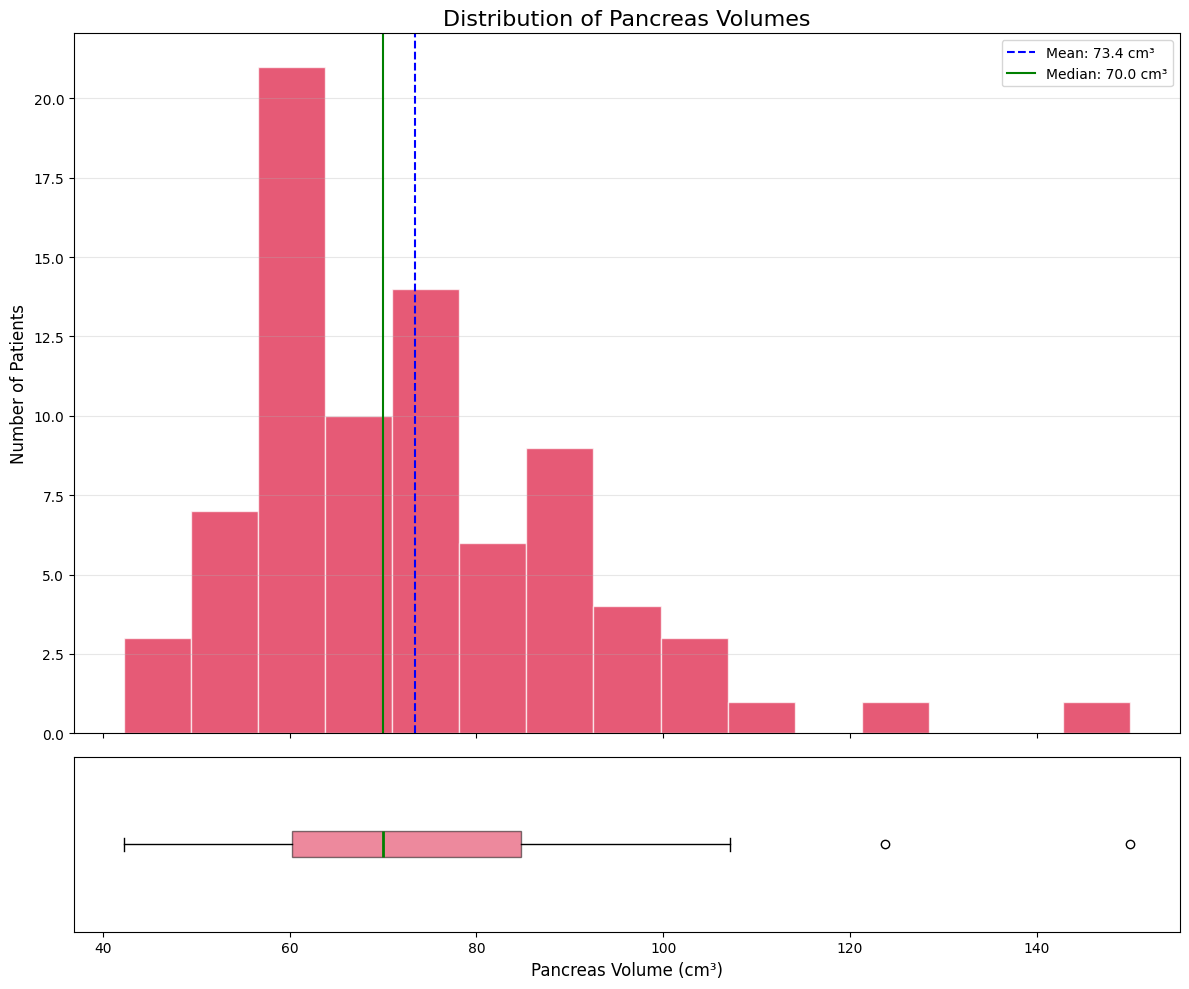

In [17]:
# Create a figure with two subplots (Histogram and Boxplot)
fig, (ax_hist, ax_box) = plt.subplots(2, 1, figsize=(12, 10), 
                                      sharex=True, 
                                      gridspec_kw={"height_ratios": (.8, .2)})

# --- 1. HISTOGRAM ---
ax_hist.hist(volumes_cm3, bins=15, color='crimson', edgecolor='white', alpha=0.7)

# Statistics for the plot
mean_vol = np.mean(volumes_cm3)
median_vol = np.median(volumes_cm3)

ax_hist.axvline(mean_vol, color='blue', linestyle='--', label=f'Mean: {mean_vol:.1f} cm³')
ax_hist.axvline(median_vol, color='green', linestyle='-', label=f'Median: {median_vol:.1f} cm³')

ax_hist.set_title("Distribution of Pancreas Volumes", fontsize=16)
ax_hist.set_ylabel("Number of Patients", fontsize=12)
ax_hist.legend()
ax_hist.grid(axis='y', alpha=0.3)

# --- 2. BOXPLOT ---
ax_box.boxplot(volumes_cm3, vert=False, patch_artist=True, 
               boxprops=dict(facecolor='crimson', alpha=0.5),
               medianprops=dict(color='green', linewidth=2))

ax_box.set_xlabel("Pancreas Volume (cm³)", fontsize=12)
ax_box.set_yticks([]) # Hide y-ticks for the boxplot

plt.tight_layout()
plt.show()

In [26]:
import numpy as np

vols = np.array(volumes_cm3)
files = np.array(all_label_files)

q1 = np.percentile(vols, 25)
q3 = np.percentile(vols, 75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

out_mask = (vols < low) | (vols > high)
out_files = files[out_mask]
out_vols = vols[out_mask]

# prendo i due più estremi tra gli outlier: minimo e massimo
min_id = out_files[np.argmin(out_vols)]
max_id = out_files[np.argmax(out_vols)]

print(min_id)
print(max_id)

label0021.nii.gz
label0061.nii.gz


## **2D SPATIAL OCCUPANCY HEATMAP OF PANCREAS LOCATION**

2D heatmap showing the spatial distribution of pancreas occurrence across patients in the axial plane. For each patient, the 3D pancreas mask was projected onto the $(x,y)$ plane by marking locations where the pancreas appears in at least one slice, and the resulting maps were aggregated across all patients. The heatmap highlights the most probable region of pancreas localization within the image.

In [18]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import os

# --- CONFIGURATION ---
labels_folder = r'C:\Users\pietr\Desktop\Progetto ai\vecchie da cancellare\TCIA_pancreas_labels-02-05-2017'
all_label_files = sorted([f for f in os.listdir(labels_folder) if f.endswith('.nii.gz')])

# Initialize a 512x512 heatmap (standard CT resolution)
heatmap_2d = np.zeros((512, 512))
num_patients = len(all_label_files)

print(f"Generating heatmap for {num_patients} patients...")

for i, file_name in enumerate(all_label_files):
    file_path = os.path.join(labels_folder, file_name)
    
    # Load the mask
    mask_obj = nib.load(file_path)
    mask_data = mask_obj.get_fdata()
    
    # Create a 2D projection: 1 if pancreas is present in ANY slice at (x,y)
    # We use np.any along the Z-axis (axis 2)
    patient_projection = np.any(mask_data > 0, axis=2).astype(float)
    
    # Add to the global heatmap
    # Note: ensure shape matches 512x512, otherwise resize or pad
    if patient_projection.shape == (512, 512):
        heatmap_2d += patient_projection
    
    if (i + 1) % 20 == 0 or (i + 1) == num_patients:
        print(f"Progress: {i+1}/{num_patients}")

print("Heatmap calculation complete.")

Generating heatmap for 80 patients...
Progress: 20/80
Progress: 40/80
Progress: 60/80
Progress: 80/80
Heatmap calculation complete.


C:\Users\pietr\AppData\Local\Temp\ipykernel_17672\386983543.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


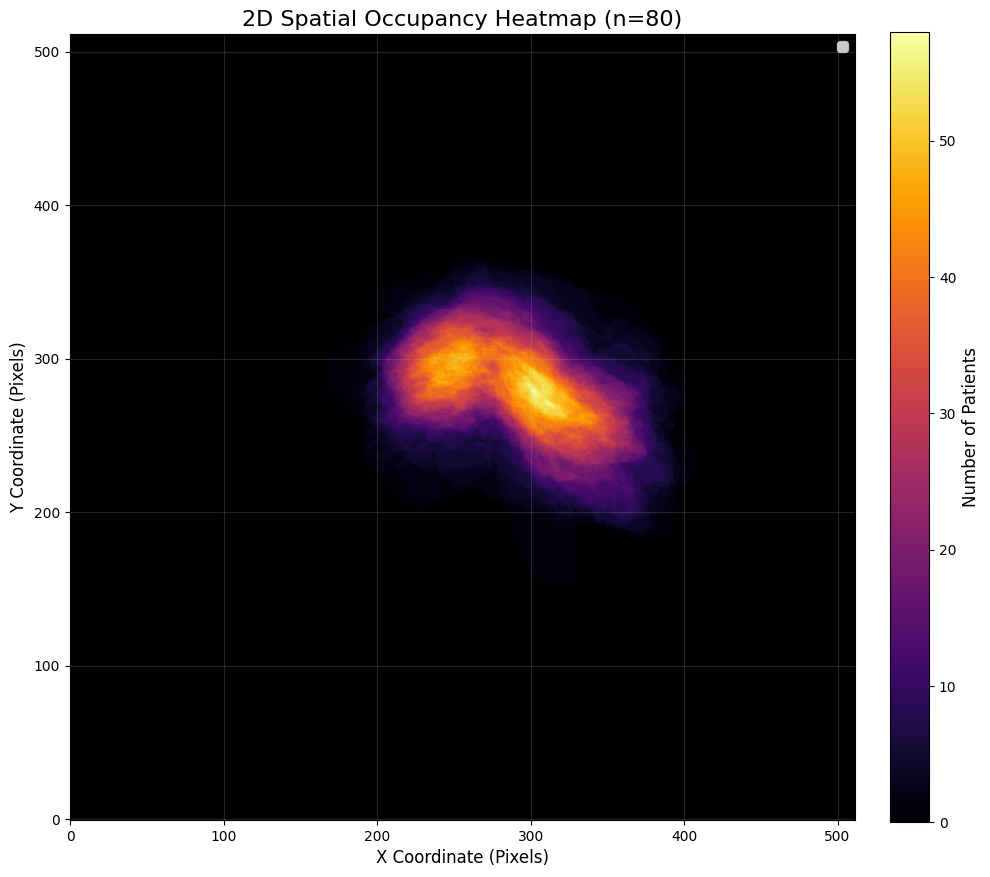

In [19]:
plt.figure(figsize=(10, 10))

# Display the heatmap
# We transpose or flip if necessary to match standard radiological view
img = plt.imshow(heatmap_2d.T, cmap='inferno', origin='lower')

# Add a colorbar to show patient count
cbar = plt.colorbar(img, fraction=0.046, pad=0.04)
cbar.set_label('Number of Patients', fontsize=12)

# Add a "Bounding Box" of the maximum occupancy area
# This helps visualize where to crop
occupied_indices = np.where(heatmap_2d > 0)
y_min, y_max = np.min(occupied_indices[0]), np.max(occupied_indices[0])
x_min, x_max = np.min(occupied_indices[1]), np.max(occupied_indices[1])



plt.title(f"2D Spatial Occupancy Heatmap (n={num_patients})", fontsize=16)
plt.xlabel("X Coordinate (Pixels)", fontsize=12)
plt.ylabel("Y Coordinate (Pixels)", fontsize=12)
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## **HOUNSFIELD UNIT (HU) DISTRIBUTION: PANCREAS VS BACKGROUND**

Histogram of Hounsfield Unit (HU) values comparing pancreas tissue and background regions. The pancreas exhibits a concentrated distribution in soft-tissue ranges, while the background spans a much wider range, including air and high-density structures. Based on this observation, intensity values were clipped to the range $[−200,300]$ during preprocessing to focus on relevant soft-tissue information and reduce the influence of outliers.

In [16]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import os
import pydicom
import random

# --- CONFIGURATION ---
labels_folder = 'vecchie da cancellare/TCIA_pancreas_labels-02-05-2017/'
dicom_base_dir = 'vecchie da cancellare/Pancreas-CT/'
all_label_files = sorted([f for f in os.listdir(labels_folder) if f.endswith('.nii.gz')])

pancreas_hu_samples = []
background_hu_samples = []

print("Sampling HU intensities from all patients (this may take a few minutes)...")

for i, label_file in enumerate(all_label_files):
    # 1. Get Patient ID from filename (e.g., label0001 -> 0001)
    patient_id = label_file.replace('label', '').replace('.nii.gz', '')
    
    # 2. Find the correct DICOM folder for this patient
    patient_dicom_dir = ""
    target_string = f"PANCREAS_{patient_id}"
    
    for root, dirs, files in os.walk(dicom_base_dir):
        if target_string in root and len(files) > 100:
            patient_dicom_dir = root
            break
            
    if not patient_dicom_dir:
        continue # Skip if folder not found

    # 3. Load DICOM Volume
    filenames = sorted([f for f in os.listdir(patient_dicom_dir) if f.endswith('.dcm')])
    slices = [pydicom.dcmread(os.path.join(patient_dicom_dir, f)) for f in filenames]
    
    # Sort slices by position (crucial for alignment)
    slices.sort(key=lambda x: float(x.ImagePositionPatient[2]))
    
    # Create 3D Volume and apply Slope/Intercept to get true HU values
    ct_volume = np.stack([s.pixel_array for s in slices])
    
    # Medical images often need rescaling: HU = pixel * slope + intercept
    slope = slices[0].RescaleSlope if 'RescaleSlope' in slices[0] else 1
    intercept = slices[0].RescaleIntercept if 'RescaleIntercept' in slices[0] else -1024
    ct_volume = ct_volume * slope + intercept

    # 4. Load Mask
    mask_data = nib.load(os.path.join(labels_folder, label_file)).get_fdata()
    # Align mask to CT (transpose/flip if needed based on your previous checks)
    mask_data = np.transpose(mask_data, (2, 1, 0)) 

    # 5. Extract Values
    # We take 1000 random samples per patient to avoid memory issues
    p_vals = ct_volume[mask_data > 0]
    if len(p_vals) > 0:
        pancreas_hu_samples.extend(random.sample(list(p_vals), min(1000, len(p_vals))))
        
    bg_vals = ct_volume[mask_data == 0]
    if len(bg_vals) > 0:
        background_hu_samples.extend(random.sample(list(bg_vals), min(1000, len(bg_vals))))

    if (i + 1) % 10 == 0:
        print(f"Processed {i+1}/{len(all_label_files)} patients...")

print("Sampling complete.")

Sampling HU intensities from all patients (this may take a few minutes)...
Processed 10/80 patients...
Processed 20/80 patients...
Processed 30/80 patients...
Processed 40/80 patients...
Processed 50/80 patients...
Processed 60/80 patients...
Processed 70/80 patients...
Processed 80/80 patients...
Sampling complete.


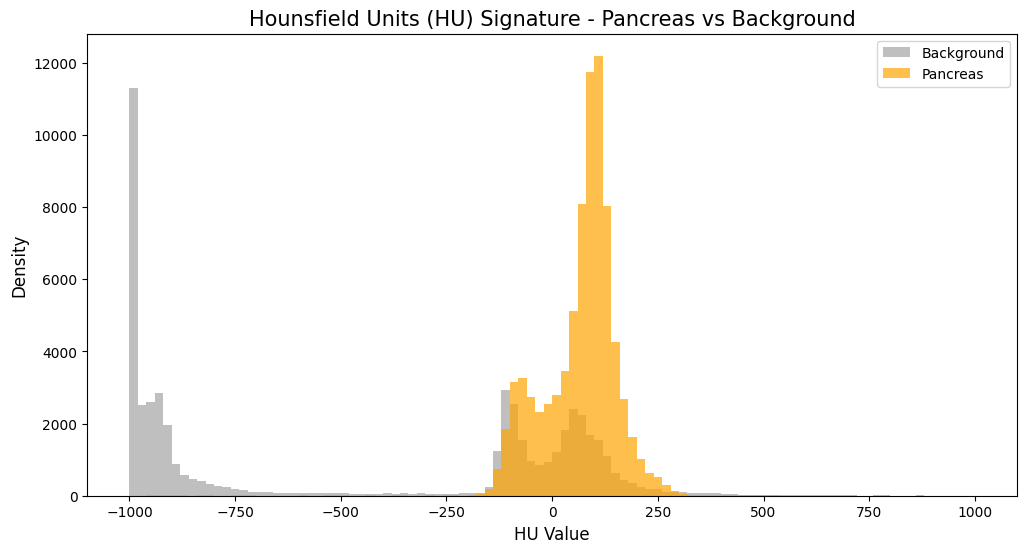

In [23]:
plt.figure(figsize=(12, 6))
hu_range = (-1000, 1000) # Focusing on soft tissues and fat

plt.hist(background_hu_samples, bins=100, range=hu_range, color='gray', 
         alpha=0.5, label='Background', density=False)
plt.hist(pancreas_hu_samples, bins=100, range=hu_range, color='orange', 
         alpha=0.7, label='Pancreas', density=False)

plt.title("Hounsfield Units (HU) Signature - Pancreas vs Background", fontsize=15)
plt.xlabel("HU Value", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend()
plt.show()